# Notebook 02 — Preprocessing Data Spasial

**Judul Penelitian:** Penentuan Lokasi Rumah Pompa Air Pengendali Banjir Menggunakan Klasterisasi DBSCAN dan K-Means (Studi Kasus: Kota Surabaya)

## Keputusan Metodologis Tahap 2 (Hasil Evaluasi Tahap 1)
Seluruh proses pada notebook ini menggunakan fungsi modular dari `src/preprocessing.py` tanpa mengubah data asli di `data/raw/`:
1. **Validasi awal & Normalisasi `kode_hierarki`**: Menyeragamkan 3 typo (`Sa`, `Sl` → `SL`).
2. **Transformasi CRS seragam**: Memproyeksikan ketiga dataset dari WGS84 (`EPSG:4326`) ke **UTM Zona 49S (`EPSG:32749`)** dalam satuan **meter** dengan kolom eksplisit **`easting` (`X1`)** dan **`northing` (`X2`)**.
3. **Point-in-Polygon (PiP) Ketat & Deterministik**:
   - **Opsi 1A**: 87 titik di zona *overlap* poligon ditetapkan secara deterministik menurut urutan `id_rayon` (`RYN-01` s.d. `RYN-07`) agar *mutually exclusive* dan *reproducible*.
   - **Opsi 2A**: 65 titik di luar seluruh poligon dikeluarkan dari input clustering dan disimpan ke file audit terpisah.
4. **Deduplikasi Koordinat Identik (Opsi 3B)**: Menyisakan tepat 1 titik representatif per koordinat unik (prioritas hierarki `SP > SS > ST > SL`, lalu `no` terkecil) agar tidak ada jarak `0 meter` pada *k-distance* / DBSCAN maupun bobot ganda centroid K-Means. Log 103 Tipe A & 27 Tipe B disimpan terpisah.
5. **Pemisahan Data Rumah Pompa**: Memisahkan `71 Operasional Aktif` (acuan analisis jarak utama, dengan catatan transparan 1 pasang koordinat identik `PMP-013`/`PMP-014`) dan `12 Pengembangan Baru` (layer tambahan terpisah).

## 1. Setup Path & Import Modul `src/preprocessing.py`

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import (
    load_raw_datasets,
    validate_geometries_and_coords,
    normalize_hierarchy_code,
    project_to_utm49s,
    assign_rayon_pip,
    deduplicate_exact_coordinates,
    prepare_pump_datasets,
    build_rekap_per_rayon,
    verify_processed_outputs,
    save_processed_outputs,
)

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
TAB_DIR = PROJECT_ROOT / "outputs" / "tables"

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 120

print("Project Root  :", PROJECT_ROOT)
print("Raw Dir       :", RAW_DIR)
print("Processed Dir :", PROCESSED_DIR)

Project Root  : C:\Skripsi\skripsi-rumah-pompa
Raw Dir       : C:\Skripsi\skripsi-rumah-pompa\data\raw
Processed Dir : C:\Skripsi\skripsi-rumah-pompa\data\processed


## 2. Membaca & Memvalidasi Ketiga Dataset Mentah (`EPSG:4326`)
Kita memastikan ketiga dataset terbaca sempurna, ber-CRS `EPSG:4326`, tidak memiliki geometri null/kosong/invalid, dan berada di dalam rentang koordinat geografis Kota Surabaya.

In [2]:
gdf_saluran_raw, gdf_rayon_raw, gdf_pompa_raw = load_raw_datasets(RAW_DIR)

valid_reports = [
    validate_geometries_and_coords(gdf_saluran_raw, "Titik Saluran Drainase"),
    validate_geometries_and_coords(gdf_rayon_raw, "Batas 7 Rayon Pematusan"),
    validate_geometries_and_coords(gdf_pompa_raw, "Lokasi Rumah Pompa (Bab III)"),
]
display(pd.DataFrame(valid_reports))

,dataset,jumlah_record,crs,geometri_null,geometri_kosong,geometri_tidak_valid,koordinat_nan_inf,dalam_rentang_surabaya,min_lon,max_lon,min_lat,max_lat
0,Titik Saluran Drainase,21467,EPSG:4326,0,0,0,0,True,112.593601,112.822846,-7.345973,-7.206662
1,Batas 7 Rayon Pematusan,7,EPSG:4326,0,0,0,0,True,112.591211,112.846573,-7.358037,-7.192732
2,Lokasi Rumah Pompa (Bab III),83,EPSG:4326,0,0,0,0,True,112.600212,112.823274,-7.347834,-7.206279


## 3. Normalisasi Typo `kode_hierarki` (`Sa`, `Sl` -> `SL`)
Kita memperbaiki 3 inkonsistensi penulisan pada `kode_hierarki` agar 100% konsisten dengan `hierarki_saluran` (4 kategori: `SP`, `SS`, `ST`, `SL`).

In [3]:
gdf_saluran_norm, df_typo_log = normalize_hierarchy_code(gdf_saluran_raw)

print(f"Jumlah baris dinormalisasi: {len(df_typo_log)}")
display(df_typo_log)

print("\nDistribusi kode_hierarki setelah normalisasi:")
display(pd.crosstab(gdf_saluran_norm["hierarki_saluran"], gdf_saluran_norm["kode_hierarki"], margins=True))

Jumlah baris dinormalisasi: 3


,no,id_titik,nama_saluran,kode_hierarki_raw,hierarki_saluran,kode_hierarki_baru
0,10966,Sa-10966,SL - 8755 - S L. Semolo Waru Selatan IX - Timur,Sa,Saluran Lokal (SL),SL
1,10967,Sa-10967,SL - 8756 - S L. Semolo Waru Selatan VIII - Utara,Sa,Saluran Lokal (SL),SL
2,11081,Sl-08408,Sl-08408 - S L. 2,Sl,Saluran Lokal (SL),SL



Distribusi kode_hierarki setelah normalisasi:


kode_hierarki,SL,SP,SS,ST,All
hierarki_saluran,,,,,
Saluran Lokal (SL),18660,0,0,0,18660
Saluran Primer (SP),0,75,0,0,75
Saluran Sekunder (SS),0,0,400,0,400
Saluran Tersier (ST),0,0,0,2332,2332
All,18660,75,400,2332,21467


## 4. Transformasi Proyeksi Koordinat (`EPSG:4326` -> `EPSG:32749`)
Seluruh dataset ditransformasikan secara seragam ke **UTM Zona 49S (`EPSG:32749`)** dalam satuan **meter**:
- `easting` = variabel `X1` (meter)
- `northing` = variabel `X2` (meter)

Kita juga membandingkan kolom baru `easting`/`northing` dengan kolom `utm_x`/`utm_y` bawaan untuk dokumentasi presisi.

In [4]:
gdf_saluran_utm = project_to_utm49s(gdf_saluran_norm, add_xy_cols=True)
gdf_rayon_utm = project_to_utm49s(gdf_rayon_raw, add_xy_cols=False)
gdf_pompa_utm = project_to_utm49s(gdf_pompa_raw, add_xy_cols=True)

# Cek selisih antara hasil proyeksi baru (easting, northing) vs utm_x/utm_y bawaan
sal_diff = np.hypot(gdf_saluran_utm["easting"] - gdf_saluran_utm["utm_x"], gdf_saluran_utm["northing"] - gdf_saluran_utm["utm_y"])
pmp_diff = np.hypot(gdf_pompa_utm["easting"] - gdf_pompa_utm["utm_x"], gdf_pompa_utm["northing"] - gdf_pompa_utm["utm_y"])

print("CRS seluruh layer setelah proyeksi:")
print(f"  Saluran : {gdf_saluran_utm.crs}")
print(f"  Rayon   : {gdf_rayon_utm.crs}")
print(f"  Pompa   : {gdf_pompa_utm.crs}")
print(f"\nRentang Easting (X1) saluran  : {gdf_saluran_utm['easting'].min():,.2f} m  s.d.  {gdf_saluran_utm['easting'].max():,.2f} m")
print(f"Rentang Northing (X2) saluran : {gdf_saluran_utm['northing'].min():,.2f} m  s.d.  {gdf_saluran_utm['northing'].max():,.2f} m")
print(f"\nSelisih maksimum vs utm_x/utm_y bawaan -> Saluran: {sal_diff.max():.4f} m | Pompa: {pmp_diff.max():.4f} m")
display(gdf_saluran_utm[["no", "id_titik", "kode_hierarki", "longitude", "latitude", "easting", "northing"]].head(5))

CRS seluruh layer setelah proyeksi:
  Saluran : EPSG:32749
  Rayon   : EPSG:32749
  Pompa   : EPSG:32749

Rentang Easting (X1) saluran  : 675,952.36 m  s.d.  701,233.15 m
Rentang Northing (X2) saluran : 9,187,636.00 m  s.d.  9,203,025.63 m

Selisih maksimum vs utm_x/utm_y bawaan -> Saluran: 0.0821 m | Pompa: 0.0785 m


,no,id_titik,kode_hierarki,longitude,latitude,easting,northing
0,1,SP-2,SP,112.661249,-7.235771,683418.071768,9.199852e+06
1,2,SP-3,SP,112.646394,-7.250882,681771.436602,9.198187e+06
2,3,SP-1,SP,112.608203,-7.228973,677562.409505,9.200625e+06
3,4,SP-4,SP,112.680899,-7.256391,685579.785630,9.197564e+06
4,5,SP-5,SP,112.677118,-7.258478,685161.373942,9.197335e+06


## 5. Pembagian Wilayah Point-in-Polygon (PiP) Ketat & Deterministik (Opsi 1A + Opsi 2A)
- **Opsi 1A**: Titik pada zona *overlap* (>1 poligon) ditetapkan secara deterministik ke `id_rayon` terkecil (`RYN-01` s.d. `RYN-07`) sehingga setiap titik hanya masuk **tepat 1 rayon** (*mutually exclusive*).
- **Opsi 2A**: Titik di luar seluruh 7 poligon dikeluarkan dari data clustering dan disimpan pada tabel audit terpisah lengkap dengan jaraknya ke batas rayon terdekat.

In [5]:
gdf_saluran_in, gdf_saluran_out, pip_summary = assign_rayon_pip(gdf_saluran_utm, gdf_rayon_utm)

print("Ringkasan Verifikasi Point-in-Polygon (EPSG:32749):")
for k, v in pip_summary.items():
    print(f"  - {k:32s}: {v:,}")

print("\nSebaran 87 titik pada zona overlap (pasangan poligon x rayon terpilih):")
overlap_sub = gdf_saluran_in[gdf_saluran_in["is_overlap_zone"]]
display(pd.crosstab(overlap_sub["overlap_rayons"], overlap_sub["nama_rayon"], margins=True))

print("\nSebaran 65 titik di luar poligon (disimpan ke file audit):")
display(
    gdf_saluran_out.groupby("rayon_terdekat_verified")["jarak_batas_terdekat_m"]
    .agg(jumlah_titik="count", jarak_min_m="min", jarak_median_m="median", jarak_max_m="max")
)

Ringkasan Verifikasi Point-in-Polygon (EPSG:32749):
  - total_awal                      : 21,467
  - dalam_poligon_within            : 21,402
  - tepat_di_batas_touches          : 0
  - di_luar_poligon                 : 65
  - titik_di_zona_overlap           : 87
  - cocok_dengan_rayon_pip_sumber   : 21,402

Sebaran 87 titik pada zona overlap (pasangan poligon x rayon terpilih):


nama_rayon,Rayon Benowo,Rayon Tandes,Rayon Wiyung,All
overlap_rayons,,,,
Rayon Benowo & Rayon Tandes,26,0,0,26
Rayon Benowo & Rayon Wiyung,52,0,0,52
Rayon Genteng & Rayon Tandes,0,3,0,3
Rayon Genteng & Rayon Wiyung,0,0,6,6
All,78,3,6,87



Sebaran 65 titik di luar poligon (disimpan ke file audit):


,jumlah_titik,jarak_min_m,jarak_median_m,jarak_max_m
rayon_terdekat_verified,,,,
Rayon Genteng,3,1.20,2.210,3.36
Rayon Gubeng,8,0.27,5.420,18.41
Rayon Jambangan,50,1.10,115.410,226.51
Rayon Tandes,4,0.50,3.925,9.05


## 6. Deduplikasi Koordinat Identik (Opsi 3B)
Kita menyisakan tepat **1 titik representatif per koordinat unik** (aturan deterministik: prioritas hierarki `SP > SS > ST > SL`, lalu `no` terkecil) agar jarak antar-titik pada setiap rayon selalu `> 0 meter`. Seluruh baris yang dihapus dicatat terpisah menurut tipenya:
- **Tipe A**: Identik penuh (`longitude`, `latitude`, `id_titik`, dan `nama_saluran` sama).
- **Tipe B**: Koordinat sama, tetapi `id_titik` atau `nama_saluran` berbeda.

In [6]:
gdf_saluran_clean, df_removed_log = deduplicate_exact_coordinates(gdf_saluran_in)

print(f"Jumlah titik sebelum deduplikasi (dalam poligon) : {len(gdf_saluran_in):,}")
print(f"Jumlah baris duplikat koordinat dihapus          : {len(df_removed_log):,}")
print(f"Jumlah titik bersih siap clustering              : {len(gdf_saluran_clean):,}")

print("\nRincian baris terhapus berdasarkan Rayon x Tipe Duplikat:")
display(pd.crosstab(df_removed_log["nama_rayon"], df_removed_log["tipe_duplikat"], margins=True))

print("\nContoh 8 baris log audit duplikat yang dihapus:")
display(df_removed_log[[
    "no", "id_titik", "nama_saluran", "nama_rayon",
    "tipe_duplikat", "no_representatif", "id_titik_representatif"
]].head(8))

Jumlah titik sebelum deduplikasi (dalam poligon) : 21,402
Jumlah baris duplikat koordinat dihapus          : 130
Jumlah titik bersih siap clustering              : 21,272

Rincian baris terhapus berdasarkan Rayon x Tipe Duplikat:


tipe_duplikat,Tipe A: Identik Penuh (ID & Nama Sama),"Tipe B: Koordinat Sama, ID/Nama Berbeda",All
nama_rayon,,,
Rayon Genteng,8,0,8
Rayon Gubeng,92,23,115
Rayon Jambangan,0,1,1
Rayon Tandes,3,3,6
All,103,27,130



Contoh 8 baris log audit duplikat yang dihapus:


,no,id_titik,nama_saluran,nama_rayon,tipe_duplikat,no_representatif,id_titik_representatif
0,1715,ST-1318,ST-1318 - S T. Teluk Bayur (Barat),Rayon Genteng,Tipe A: Identik Penuh (ID & Nama Sama),1714,ST-1318
1,1717,ST-1319,ST-1319 - S T. Teluk Bayur (Timur),Rayon Genteng,Tipe A: Identik Penuh (ID & Nama Sama),1716,ST-1319
2,1723,ST-1324,ST-1324 - S T. Teluk Buli Buntu,Rayon Genteng,Tipe A: Identik Penuh (ID & Nama Sama),1722,ST-1324
3,1725,ST-1325,ST-1325 - S T. Teluk Kumai Barat (Barat),Rayon Genteng,Tipe A: Identik Penuh (ID & Nama Sama),1724,ST-1325
4,1727,ST-1326,ST-1326 - S T. Teluk Kumai Barat (Timur),Rayon Genteng,Tipe A: Identik Penuh (ID & Nama Sama),1726,ST-1326
5,1729,ST-1327,ST-1327 - S T. Teluk Kumai Tengah (Barat),Rayon Genteng,Tipe A: Identik Penuh (ID & Nama Sama),1728,ST-1327
6,1732,ST-1328,ST-1328 - S T. Teluk Pang Pang (Selatan),Rayon Genteng,Tipe A: Identik Penuh (ID & Nama Sama),1731,ST-1328
7,1737,ST-1331,ST-1331 - S T. Teluk Sarera (Timur),Rayon Genteng,Tipe A: Identik Penuh (ID & Nama Sama),1736,ST-1331


## 7. Pemisahan Data Rumah Pompa (71 Operasional Aktif vs 12 Pengembangan Baru)
Sesuai metodologi:
- **71 lokasi `Operasional Aktif`** menjadi acuan utama perhitungan jarak Euclidean pada Tahap 6 (dengan flag transparan `is_duplicate_coord = True` pada `PMP-013` & `PMP-014` yaitu *P.A Bozem Moro Krembangan I*).
- **12 lokasi `Pengembangan Baru`** disimpan sebagai layer terpisah (tidak dicampur ke analisis jarak utama).

In [7]:
gdf_pompa_all, gdf_pompa_aktif, gdf_pompa_pengembangan = prepare_pump_datasets(gdf_pompa_utm)

print(f"Total rumah pompa        : {len(gdf_pompa_all)} entri")
print(f"  - Operasional Aktif    : {len(gdf_pompa_aktif)} entri ({gdf_pompa_aktif[['easting', 'northing']].drop_duplicates().shape[0]} koordinat unik)")
print(f"  - Pengembangan Baru    : {len(gdf_pompa_pengembangan)} entri ({gdf_pompa_pengembangan[['easting', 'northing']].drop_duplicates().shape[0]} koordinat unik)")

print("\nCatatan transparan entri dengan flag is_duplicate_coord = True:")
display(gdf_pompa_aktif.loc[
    gdf_pompa_aktif["is_duplicate_coord"],
    ["no", "id_pompa", "name", "rayon_pematusan", "easting", "northing", "status_fasilitas"]
])

Total rumah pompa        : 83 entri
  - Operasional Aktif    : 71 entri (70 koordinat unik)
  - Pengembangan Baru    : 12 entri (12 koordinat unik)

Catatan transparan entri dengan flag is_duplicate_coord = True:


,no,id_pompa,name,rayon_pematusan,easting,northing,status_fasilitas
62,74,PMP-013,P.A Bozem Moro Krembangan I,Rayon Tandes,688678.150656,9.201211e+06,Operasional Aktif
63,75,PMP-014,P.A Bozem Moro Krembangan I,Rayon Tandes,688678.150656,9.201211e+06,Operasional Aktif


## 8. Rekapitulasi Sebelum vs Sesudah Preprocessing per Rayon & Validasi Otomatis
Kita menampilkan tabel rekapitulasi lengkap untuk dokumentasi Bab III, memverifikasi syarat pasca-preprocessing (CRS seragam `EPSG:32749`, 0 missing value, 0 duplikat koordinat, dan jarak tetangga terdekat `NN-1 > 0 m` di seluruh 7 rayon), lalu menyimpan seluruh keluaran ke `data/processed/` dan `outputs/tables/`.

In [8]:
# 8a. Tabel rekapitulasi sebelum vs sesudah preprocessing
df_rekap = build_rekap_per_rayon(
    gdf_rayon_utm=gdf_rayon_utm,
    gdf_in_polygon=gdf_saluran_in,
    gdf_out_polygon=gdf_saluran_out,
    gdf_clean=gdf_saluran_clean,
    df_removed_log=df_removed_log,
    gdf_pompa_aktif=gdf_pompa_aktif,
    gdf_pompa_pengembangan=gdf_pompa_pengembangan,
)
print("=== TABEL REKAPITULASI PREPROCESSING PER RAYON ===")
display(df_rekap)

# 8b. Validasi otomatis pasca-preprocessing (termasuk cek NN-1 > 0 m per rayon)
df_nn_check = verify_processed_outputs(
    gdf_clean=gdf_saluran_clean,
    gdf_rayon_utm=gdf_rayon_utm,
    gdf_pompa_aktif=gdf_pompa_aktif,
    gdf_pompa_pengembangan=gdf_pompa_pengembangan,
)
print("\n=== VALIDASI OTOMATIS PASCA-PREPROCESSING: LULUS SEMUA ASSERTION ===")
display(df_nn_check)

# 8c. Simpan seluruh output ke data/processed/ dan outputs/tables/
saved_paths = save_processed_outputs(
    processed_dir=PROCESSED_DIR,
    tables_dir=TAB_DIR,
    gdf_clean=gdf_saluran_clean,
    gdf_outside=gdf_saluran_out,
    gdf_rayon_utm=gdf_rayon_utm,
    gdf_pompa_all=gdf_pompa_all,
    gdf_pompa_aktif=gdf_pompa_aktif,
    gdf_pompa_pengembangan=gdf_pompa_pengembangan,
    df_typo_log=df_typo_log,
    df_removed_log=df_removed_log,
    df_rekap=df_rekap,
)
print("\nFile keluaran berhasil disimpan:")
for key, path in saved_paths.items():
    print(f"  - {key:28s}: {path.relative_to(PROJECT_ROOT)} ({path.stat().st_size:,} bytes)")

=== TABEL REKAPITULASI PREPROCESSING PER RAYON ===

,id_rayon,nama_rayon,luas_utm49s_km2,sebelum_pip_terdekat,dikeluarkan_luar_poligon,setelah_pip_ketat,catatan_zona_overlap,dihapus_duplikat_tipe_a,dihapus_duplikat_tipe_b,total_dihapus_duplikat,sesudah_preprocessing_siap_cluster,pompa_aktif,pompa_pengembangan
0,RYN-01,Rayon Benowo,48.64,1175,0,1175,78,0,0,0,1175,2,0
1,RYN-02,Rayon Tandes,51.38,2647,4,2643,3,3,3,6,2637,5,1
2,RYN-03,Rayon Wiyung,55.88,1123,0,1123,6,0,0,0,1123,5,0
3,RYN-04,Rayon Jambangan,31.25,2607,50,2557,0,0,1,1,2556,11,6
4,RYN-05,Rayon Rungkut,56.03,2120,0,2120,0,0,0,0,2120,15,1
5,RYN-06,Rayon Genteng,27.95,3729,3,3726,0,8,0,8,3718,14,1
6,RYN-07,Rayon Gubeng,69.86,8066,8,8058,0,92,23,115,7943,19,3
7,TOTAL,Seluruh Kota Surabaya (7 Rayon),340.99,21467,65,21402,87,103,27,130,21272,71,12



=== VALIDASI OTOMATIS PASCA-PREPROCESSING: LULUS SEMUA ASSERTION ===


,nama_rayon,jumlah_titik_unik,jarak_nn1_min_m,jarak_nn1_median_m
0,Rayon Benowo,1175,1.1278,6.88
1,Rayon Genteng,3718,1.9674,22.69
2,Rayon Gubeng,7943,0.1105,8.93
3,Rayon Jambangan,2556,1.0190,16.44
4,Rayon Rungkut,2120,0.9938,14.04
5,Rayon Tandes,2637,1.3271,7.85
6,Rayon Wiyung,1123,2.3245,10.06



File keluaran berhasil disimpan:
  - saluran_clean_gpkg          : data\processed\saluran_clean_utm49s.gpkg (6,852,608 bytes)
  - saluran_luar_poligon_gpkg   : data\processed\saluran_luar_poligon_audit_utm49s.gpkg (118,784 bytes)
  - rayon_utm49s_gpkg           : data\processed\rayon_pematusan_utm49s.gpkg (135,168 bytes)
  - pompa_all_gpkg              : data\processed\rumah_pompa_all_utm49s.gpkg (122,880 bytes)
  - pompa_aktif_gpkg            : data\processed\rumah_pompa_aktif_utm49s.gpkg (110,592 bytes)
  - pompa_pengembangan_gpkg     : data\processed\rumah_pompa_pengembangan_utm49s.gpkg (98,304 bytes)
  - saluran_clean_csv           : data\processed\saluran_clean_utm49s.csv (5,280,928 bytes)
  - pompa_aktif_csv             : data\processed\rumah_pompa_aktif_utm49s.csv (11,306 bytes)
  - pompa_pengembangan_csv      : data\processed\rumah_pompa_pengembangan_utm49s.csv (2,391 bytes)
  - rekap_preprocessing_csv     : outputs\tables\02_rekap_preprocessing_per_rayon.csv (753 bytes)
  - a

## 9. Visualisasi Rekapitulasi Sebelum vs Sesudah Preprocessing (`outputs/figures/`)

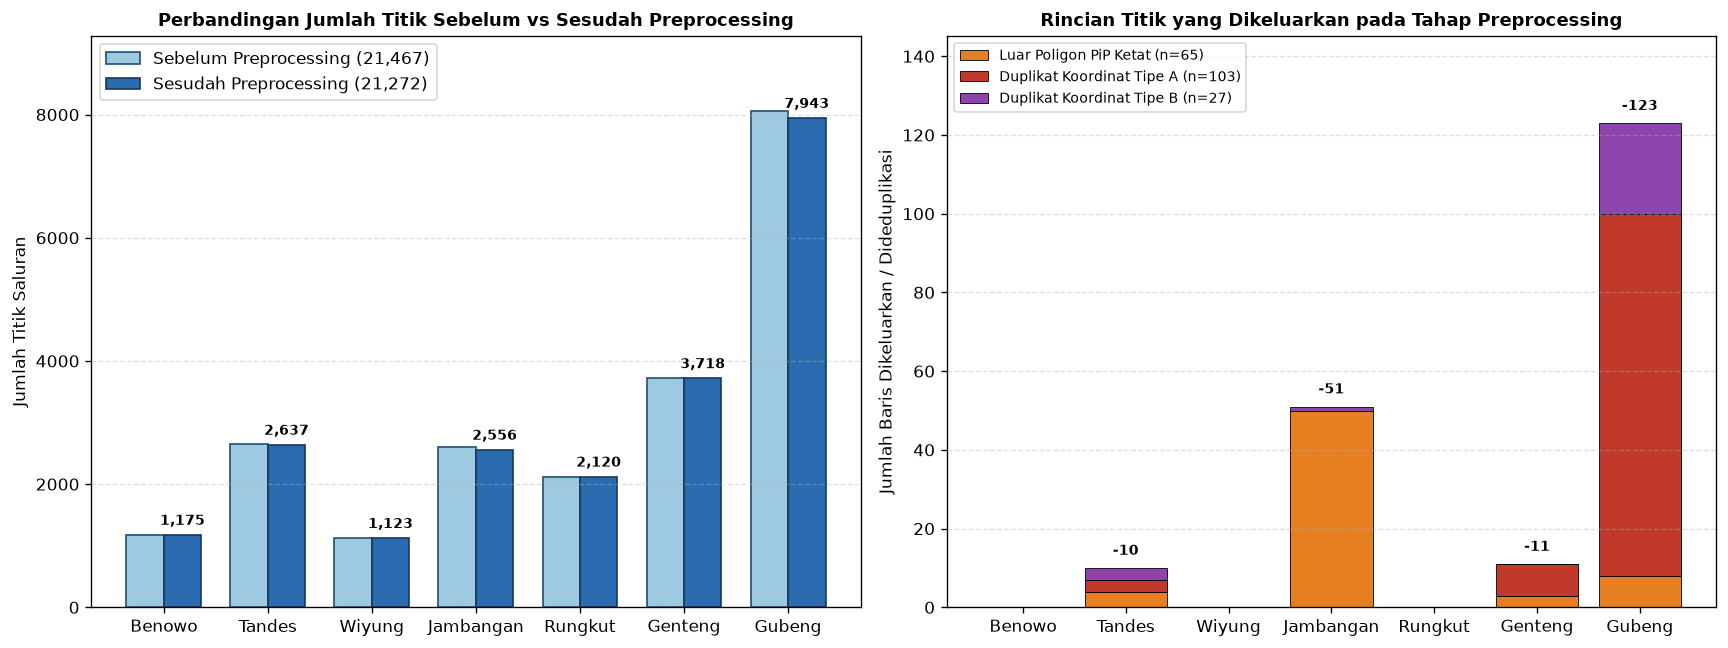

Grafik rekapitulasi disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\figures\02_rekap_preprocessing.png


In [9]:
df_plot = df_rekap[df_rekap["id_rayon"] != "TOTAL"].copy()
short_names = [n.replace("Rayon ", "") for n in df_plot["nama_rayon"]]
x = np.arange(len(short_names))

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5))

# Panel Kiri: Perbandingan jumlah titik sebelum vs sesudah preprocessing
ax = axes[0]
w = 0.36
b1 = ax.bar(x - w/2, df_plot["sebelum_pip_terdekat"], width=w, label=f"Sebelum Preprocessing ({int(df_plot['sebelum_pip_terdekat'].sum()):,})", color="#9ECAE1", edgecolor="#1F4E79")
b2 = ax.bar(x + w/2, df_plot["sesudah_preprocessing_siap_cluster"], width=w, label=f"Sesudah Preprocessing ({int(df_plot['sesudah_preprocessing_siap_cluster'].sum()):,})", color="#2B6CB0", edgecolor="#1A365D")
for b in b2:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width()/2, h + 110, f"{int(h):,}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(short_names)
ax.set_ylabel("Jumlah Titik Saluran")
ax.set_ylim(0, df_plot["sebelum_pip_terdekat"].max() * 1.15)
ax.set_title("Perbandingan Jumlah Titik Sebelum vs Sesudah Preprocessing", fontsize=11, fontweight="bold")
ax.legend(frameon=True)
ax.grid(axis="y", linestyle="--", alpha=0.4)

# Panel Kanan: Rincian titik yang dikeluarkan per rayon (Luar Poligon vs Duplikat Tipe A & B)
ax = axes[1]
out_vals = df_plot["dikeluarkan_luar_poligon"].values
dup_a_vals = df_plot["dihapus_duplikat_tipe_a"].values
dup_b_vals = df_plot["dihapus_duplikat_tipe_b"].values

ax.bar(short_names, out_vals, label=f"Luar Poligon PiP Ketat (n={out_vals.sum()})", color="#E67E22", edgecolor="black", linewidth=0.5)
ax.bar(short_names, dup_a_vals, bottom=out_vals, label=f"Duplikat Koordinat Tipe A (n={dup_a_vals.sum()})", color="#C0392B", edgecolor="black", linewidth=0.5)
ax.bar(short_names, dup_b_vals, bottom=out_vals + dup_a_vals, label=f"Duplikat Koordinat Tipe B (n={dup_b_vals.sum()})", color="#8E44AD", edgecolor="black", linewidth=0.5)

totals_rem = out_vals + dup_a_vals + dup_b_vals
for idx_r, tot in enumerate(totals_rem):
    if tot > 0:
        ax.text(idx_r, tot + 2.5, f"-{int(tot)}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax.set_ylabel("Jumlah Baris Dikeluarkan / Dideduplikasi")
ax.set_ylim(0, totals_rem.max() * 1.18)
ax.set_title("Rincian Titik yang Dikeluarkan pada Tahap Preprocessing", fontsize=11, fontweight="bold")
ax.legend(frameon=True, fontsize=8.5)
ax.grid(axis="y", linestyle="--", alpha=0.4)

fig_path = FIG_DIR / "02_rekap_preprocessing.png"
plt.tight_layout()
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Grafik rekapitulasi disimpan ke: {fig_path}")